[1.         0.88794508 0.77649827 0.66555879 0.55503691 0.44486711
 0.33492929 0.22490078 0.11425988 0.         0.10796234 0.21954366
 0.33173738 0.44402178 0.5560742  0.66777454 0.77905728 0.8898327
 1.        ]
[ 1.10240140e-17  1.93952007e-03  2.21438415e-03  7.47762949e-04
 -2.34757425e-03 -6.75826688e-03 -1.20648926e-02 -1.72031403e-02
 -1.98048088e-02  0.00000000e+00  4.46978613e-02  6.05952105e-02
  6.75619459e-02  6.79662685e-02  6.29791614e-02  5.34479497e-02
  3.97307724e-02  2.19403990e-02 -1.10240140e-17]


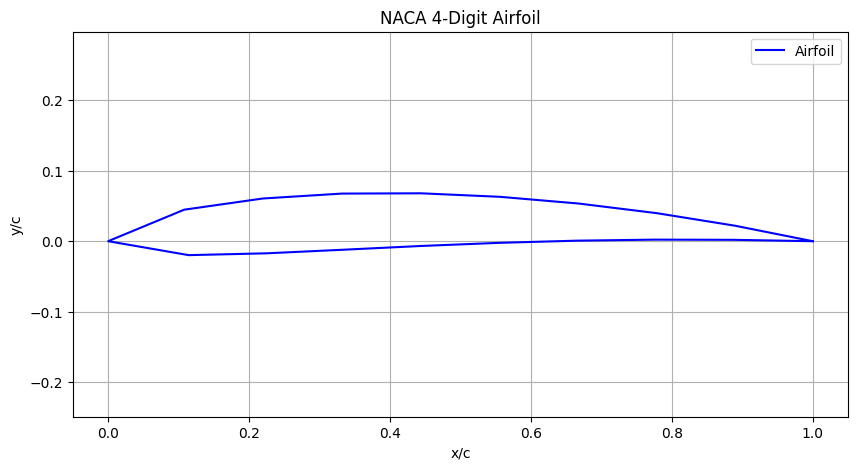

In [16]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(1)

m = np.random.uniform(0.01, 0.06)
p = np.random.uniform(0.20, 0.60)
t = np.random.uniform(0.08, 0.18)
def naca(n):
  n=int(n/2)
  x = np.linspace(0, 1, n)

  yt = 5 * t * ( 0.2969 * np.sqrt(x)- 0.1260 * x- 0.3516 * x**2+ 0.2843 * x**3 - 0.1036 * x**4)

  yc = np.zeros(n)
  dyc_dx = np.zeros(n)

  for i in range(len(x)):

      if x[i] <= p:

          yc[i] = (m / p**2) * (2 * p * x[i] - x[i]**2)
          dyc_dx[i] = (2 * m / p**2) * (p - x[i])

      else:

          yc[i] = (m / (1 - p)**2) * ((1 - 2 * p)+ 2 * p * x[i]- x[i]**2)
          dyc_dx[i] = (2 * m / (1 - p)**2) * ( p - x[i])

  theta = np.arctan(dyc_dx)

  xu = x - yt * np.sin(theta)
  yu = yc + yt * np.cos(theta)

  xl = x + yt * np.sin(theta)
  yl = yc - yt * np.cos(theta)

  xl1=np.flip(xl)
  xcurve=np.concatenate((xl1 , xu[1:]))
  yl1=np.flip(yl)
  ycurve=np.concatenate((yl1 , yu[1:]))
  print(xcurve)
  print(ycurve)

  return xcurve,ycurve

xcurve , ycurve =naca(20)

plt.figure(figsize=(10, 5))

plt.plot(xcurve, ycurve, 'b-', label='Airfoil')

plt.xlabel('x/c')
plt.ylabel('y/c')
plt.title('NACA 4-Digit Airfoil')

plt.axis('equal')
plt.grid()
plt.legend()
plt.show()


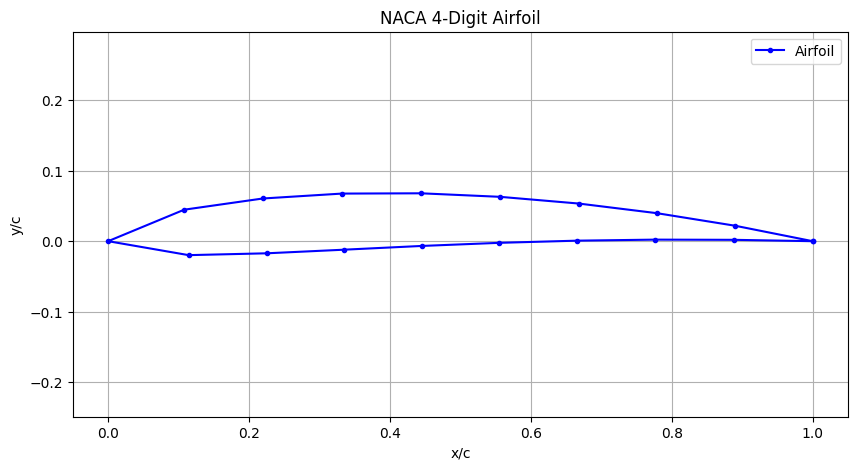

In [17]:

plt.figure(figsize=(10, 5))

plt.plot(xcurve, ycurve, 'b-o' , markersize=3 ,label='Airfoil')

plt.xlabel('x/c')
plt.ylabel('y/c')
plt.title('NACA 4-Digit Airfoil')

plt.axis('equal')
plt.grid()
plt.legend()
plt.show()


<Figure size 1000x500 with 0 Axes>

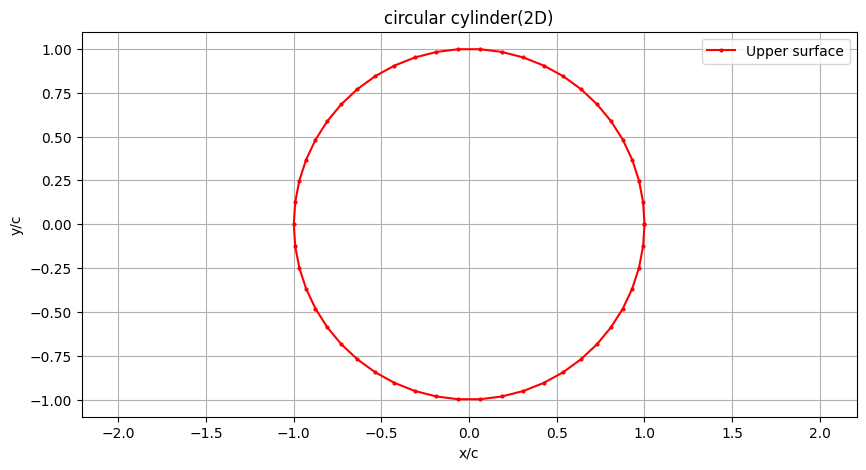

In [26]:
def cylinder(r,n):
  theta=np.linspace(2*np.pi, 0, n+1)
  r=1
  a=r*np.cos(theta)
  b=r*np.sin(theta)
  plt.figure(figsize=(10, 5))
  return a,b

xb,yb=cylinder(1,50)

plt.figure(figsize=(10, 5))
plt.plot(xb, yb, 'r-o', label='Upper surface' , markersize=2)

plt.xlabel('x/c')
plt.ylabel('y/c')
plt.title('circular cylinder(2D)')
plt.axis('equal')
plt.grid()
plt.legend()
plt.show()

In [23]:
##DEFINE PANEL GEOMETRY

def geometry(xb , yb):
  dx=np.diff(xb)
  dy=np.diff(yb)

  ##Finding midpoint
  xc=0.5*(xb[:-1] + xb[1:])
  yc=0.5*(yb[:-1] + yb[1:])

  ##calculating length  of panel
  s=np.sqrt(dx**2 + dy**2)
  print("length of panel:",s)

  ##calculating angle
  theta=np.arctan(dy/dx)
  print("angle:",theta)


  return xc,yc,dx,dy,s,theta

xc,yc,dx,dy,s,theta=geometry(a,b)

length of panel: [0.12558104 0.12558104 0.12558104 0.12558104 0.12558104 0.12558104
 0.12558104 0.12558104 0.12558104 0.12558104 0.12558104 0.12558104
 0.12558104 0.12558104 0.12558104 0.12558104 0.12558104 0.12558104
 0.12558104 0.12558104 0.12558104 0.12558104 0.12558104 0.12558104
 0.12558104 0.12558104 0.12558104 0.12558104 0.12558104 0.12558104
 0.12558104 0.12558104 0.12558104 0.12558104 0.12558104 0.12558104
 0.12558104 0.12558104 0.12558104 0.12558104 0.12558104 0.12558104
 0.12558104 0.12558104 0.12558104 0.12558104 0.12558104 0.12558104
 0.12558104 0.12558104]
angle: [ 1.50796447  1.38230077  1.25663706  1.13097336  1.00530965  0.87964594
  0.75398224  0.62831853  0.50265482  0.37699112  0.25132741  0.12566371
 -0.         -0.12566371 -0.25132741 -0.37699112 -0.50265482 -0.62831853
 -0.75398224 -0.87964594 -1.00530965 -1.13097336 -1.25663706 -1.38230077
 -1.50796447  1.50796447  1.38230077  1.25663706  1.13097336  1.00530965
  0.87964594  0.75398224  0.62831853  0.50265482  0